# Position Fitting Study (Straight-Line Track Guess)

This notebook investigates the systematic biases introduced when approximating the detailed stochastic trajectory of a muon track as a straight line between its start and endpoints.

It implements two study options:
- **Option A:** Constant $dE/dx$ set to the mean value of `1.887 MeV/cm`.
- **Option B:** Segment-by-segment $dE/dx$ fitting where the straight line is first partitioned into typical-sized segments (e.g., 10 cm), allowing per-segment $dE/dx$ parameter optimization.

In [1]:
import sys, os
PROJECT = '/sdf/group/neutrino/pgranger/larnd-sim-jax'
sys.path.insert(0, PROJECT)
sys.path.insert(0, f'{PROJECT}/src')
os.chdir(PROJECT)

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import h5py

from larndsim.consts_jax import build_params_class, load_detector_properties, load_lut
from optimize.strategies import LUTSimulation, LUTProbabilisticSimulation, ProbabilisticLossStrategy
from optimize.dataio import TracksDataset, np_from_structured, chop_tracks
from optimize.ranges import ranges
from optimize.dedx_utils import split_student_t_nll, DEDX_SPLIT_NU_L, DEDX_SPLIT_NU_R, DEDX_SPLIT_SCALE_L, DEDX_SPLIT_SCALE_R

print('JAX devices:', jax.devices())

JAX devices: [CudaDevice(id=0)]


## 1. Load and Filter Input Dataset

We load through-going muon tracks and filter to find a long track with significant energy deposition.

In [2]:
INPUT_FILE = '/sdf/data/neutrino/cyifan/diffsim_input/true_through_muon_edep_10cm_vol1cm.h5'
dataset = TracksDataset(filename=INPUT_FILE, nevents=-1, electron_sampling_resolution=0.1, chopped=False, pad=False)

print(f'Loaded {len(dataset)} trajectories.')

# Let's print properties of some trajectories to find a suitable one
for i in range(min(5, len(dataset))):
    traj_indices = dataset.batch_traj_indices[i]
    rows_list = [dataset.trajectory_row_indices[t] for t in traj_indices]
    rows = np.concatenate(rows_list)
    selected_struct = dataset.tracks_struct[rows]
    tot_de = selected_struct['dE'].sum()
    # compute total straight-line length
    start_pos = np.array([selected_struct['x_start'][0], selected_struct['y_start'][0], selected_struct['z_start'][0]])
    end_pos = np.array([selected_struct['x_end'][-1], selected_struct['y_end'][-1], selected_struct['z_end'][-1]])
    length = np.linalg.norm(end_pos - start_pos)
    print(f'Traj {i}: {len(rows)} segments, Total dE={tot_de:.2f} MeV, Straight-line length={length:.2f} cm')

INFO:optimize.dataio:-- The used simulation data includes a total track length of 3630936.6377038956 cm.
INFO:optimize.dataio:-- The number of simulation batches is 57890.


Loaded 57890 trajectories.
Traj 0: 11 segments, Total dE=89.94 MeV, Straight-line length=14.17 cm
Traj 1: 13 segments, Total dE=79.85 MeV, Straight-line length=10.96 cm
Traj 2: 17 segments, Total dE=106.20 MeV, Straight-line length=132.38 cm
Traj 3: 25 segments, Total dE=146.77 MeV, Straight-line length=64.32 cm
Traj 4: 28 segments, Total dE=157.68 MeV, Straight-line length=99.88 cm


Let's select Trajectory 0 for our study.

In [3]:
TRAJ_IDX = 0
traj_indices = dataset.batch_traj_indices[TRAJ_IDX]
rows = np.concatenate([dataset.trajectory_row_indices[t] for t in traj_indices])
selected_struct = dataset.tracks_struct[rows]
true_track_np = np_from_structured(selected_struct)
fields = dataset.get_track_fields()
print(f'Selected Trajectory {TRAJ_IDX} with fields:', fields)

Selected Trajectory 0 with fields: ('eventID', 'vertex_id', 'file_vertex_id', 'segment_id', 'z_end', 'trackID', 'file_traj_id', 'tran_diff', 'z_start', 'x_end', 'y_end', 'n_electrons', 'pdg_id', 'x_start', 'y_start', 't_start', 't0_start', 't0_end', 't0', 'dx', 'long_diff', 'pixel_plane', 't_end', 'dEdx', 'dE', 't', 'y', 'x', 'z', 'n_photons')


## 2. Straight-Line Guess Construction

We split the straight line connecting the track's start and end points into segments of a typical length (10 cm).

In [4]:
def make_straight_line_guess(true_track, fields, segment_length=10.0):
    x_start = true_track[0, fields.index('x_start')]
    y_start = true_track[0, fields.index('y_start')]
    z_start = true_track[0, fields.index('z_start')]
    
    x_end = true_track[-1, fields.index('x_end')]
    y_end = true_track[-1, fields.index('y_end')]
    z_end = true_track[-1, fields.index('z_end')]
    
    start_pos = np.array([x_start, y_start, z_start])
    end_pos = np.array([x_end, y_end, z_end])
    
    direction = end_pos - start_pos
    total_len = np.linalg.norm(direction)
    direction_unit = direction / (total_len + 1e-10)
    
    # Number of segments of length typical_length
    n_segs = int(np.ceil(total_len / segment_length))
    step_size = total_len / n_segs
    
    # Total dE
    total_de = true_track[:, fields.index('dE')].sum()
    de_per_seg = total_de / n_segs
    
    guess_track = np.zeros((n_segs, len(fields)), dtype=np.float32)
    
    for col_name in ['eventID', 'trackID', 'pdgID', 't0']:
        if col_name in fields:
            guess_track[:, fields.index(col_name)] = true_track[0, fields.index(col_name)]
            
    for i in range(n_segs):
        seg_start = start_pos + i * step_size * direction_unit
        seg_end = start_pos + (i + 1) * step_size * direction_unit
        
        guess_track[i, fields.index('x_start')] = seg_start[0]
        guess_track[i, fields.index('y_start')] = seg_start[1]
        guess_track[i, fields.index('z_start')] = seg_start[2]
        
        guess_track[i, fields.index('x_end')] = seg_end[0]
        guess_track[i, fields.index('y_end')] = seg_end[1]
        guess_track[i, fields.index('z_end')] = seg_end[2]
        
        guess_track[i, fields.index('x')] = 0.5 * (seg_start[0] + seg_end[0])
        guess_track[i, fields.index('y')] = 0.5 * (seg_start[1] + seg_end[1])
        guess_track[i, fields.index('z')] = 0.5 * (seg_start[2] + seg_end[2])
        
        guess_track[i, fields.index('dE')] = de_per_seg
        guess_track[i, fields.index('dx')] = step_size
        if 'dEdx' in fields:
            guess_track[i, fields.index('dEdx')] = de_per_seg / step_size
        
    return guess_track

guess_track_np = make_straight_line_guess(true_track_np, fields, segment_length=10.0)
print(f'True track has {true_track_np.shape[0]} segments.')
print(f'Guess track has {guess_track_np.shape[0]} segments (10 cm typical length).')

True track has 11 segments.
Guess track has 2 segments (10 cm typical length).


## 3. Spatial Diagnostics & Visualization

We finely chop both tracks to compare physical point distributions and compute spatial deviations.

In [5]:
# Finely chop both tracks to compare physical point distributions (Plotly visualization)
true_chopped, _ = chop_tracks(true_track_np, fields, precision=0.1)
guess_chopped, parent_ids = chop_tracks(guess_track_np, fields, precision=0.1)

true_chopped = np.asarray(true_chopped)
guess_chopped = np.asarray(guess_chopped)

# safe column extraction
xyz_idxs = [fields.index('x'), fields.index('y'), fields.index('z')]
guess_pts = np.take(guess_chopped, xyz_idxs, axis=1)
true_pts = np.take(true_chopped, xyz_idxs, axis=1)

# distances: for each guess point find min distance to true points
d2 = np.sum((guess_pts[:, None, :] - true_pts[None, :, :])**2, axis=2)
min_dists = np.sqrt(np.min(d2, axis=1))

mean_dev = float(min_dists.mean())
max_dev = float(min_dists.max())
rmse_dev = float(np.sqrt((min_dists**2).mean()))

print(f'Mean deviation: {mean_dev:.4f} cm')
print(f'Max  deviation: {max_dev:.4f} cm')
print(f'RMSE deviation: {rmse_dev:.4f} cm')

# Plotly 3D interactive scatter
import plotly.graph_objects as go

trace_true = go.Scatter3d(
    x=true_pts[:, 0], y=true_pts[:, 1], z=true_pts[:, 2],
    mode='markers', marker=dict(size=2, color='blue', opacity=0.7),
    name='True Track'
)

trace_guess = go.Scatter3d(
    x=guess_pts[:, 0], y=guess_pts[:, 1], z=guess_pts[:, 2],
    mode='markers+lines', marker=dict(size=3, color='red'),
    line=dict(width=2, color='red'), name='Straight-line Guess'
)

title = f'True Track vs Straight-Line Guess — mean={mean_dev:.3f} cm, max={max_dev:.3f} cm, rmse={rmse_dev:.3f} cm'
layout = go.Layout(
    title=title,
    scene=dict(
        xaxis=dict(title='X [cm]'),
        yaxis=dict(title='Y [cm]'),
        zaxis=dict(title='Z [cm]')
    ),
    legend=dict(x=0.02, y=0.98),
    margin=dict(l=0, r=0, b=0, t=40)
)

fig = go.Figure(data=[trace_true, trace_guess], layout=layout)
fig.show()

Mean deviation: 0.0233 cm
Max  deviation: 0.2272 cm
RMSE deviation: 0.0326 cm


## 4. Setup Simulation and Target Generation

In [6]:
LUT_FILE = 'src/larndsim/detector_properties/response_44_v2a_full_tick.npz'
DET_PROPS = 'src/larndsim/detector_properties/module0.yaml'
PIX_LAYOUT = 'src/larndsim/pixel_layouts/multi_tile_layout-2.4.16_v4.yaml'
RELEVANT_PARAMS = ['Ab','kb','lifetime','tran_diff','long_diff','eField','shift_x','shift_y','shift_z']

ParamsClass = build_params_class(RELEVANT_PARAMS)
ref_params = load_detector_properties(ParamsClass, DET_PROPS, PIX_LAYOUT)
ref_params = ref_params.replace(
    electron_sampling_resolution=0.1,
    number_pix_neighbors=4,
    signal_length=150,
    time_window=150,
    excess_offset=0.0,
    smooth_sigma_scale=1.0
)
response, ref_params = load_lut(LUT_FILE, ref_params)
current_params = ref_params.replace(**{p: ranges[p]['nom'] for p in RELEVANT_PARAMS})

# Create strategies
sim_strategy = LUTSimulation(response)
prob_strategy = LUTProbabilisticSimulation(response)

# Pad target shapes for static compile
sim_strategy.padded_small_nb = 256
sim_strategy.padded_large_nb = 256
prob_strategy.padded_small_nb = 256
prob_strategy.padded_large_nb = 256

# Generate the STOCHASTIC target (reference target)
true_chopped_jax = jax.device_put(true_chopped)
target_pred = sim_strategy.predict(current_params, true_chopped_jax, fields, rngkey=42)

# Extract target hit coordinates
target = {
    'pixel_id': target_pred['hit_pixels'],
    'ticks': target_pred['ticks'],
    'adcs': target_pred['adcs']
}
print(f'Target generated with {len(target["pixel_id"])} hits.')

INFO:larndsim.consts_jax:Loading response from npz file
/usr/local/lib/python3.10/dist-packages/jax/_src/numpy/array_methods.py:122: UserWarning: Explicitly requested dtype <class 'jax.numpy.int64'> requested in astype is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return lax_numpy.astype(self, dtype, copy=copy, device=device)
/sdf/group/neutrino/pgranger/larnd-sim-jax/src/larndsim/detsim_jax.py:274: UserWarning: Explicitly requested dtype <class 'jax.numpy.int64'> requested in array is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return jnp.where(outside, jnp.array(-1, dtype=jnp.int64), pid)
INFO:larndsim.sim_jax:Pad

Target generated with 193 hits.


## 5. Compute NLL Loss Scans

We will scan the spatial parameter `shift_x` and calculate the Point Process NLL loss.

INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0


NLL at nominal (Option A - Mean dEdx): 2904.1455078125


INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (28,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (29,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad v

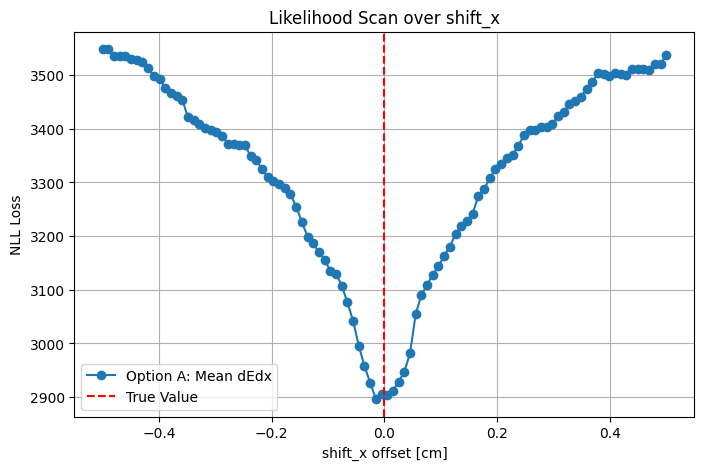

Scan Minimum Offset: -0.015151515151515138


In [7]:
loss_strategy = ProbabilisticLossStrategy(sigma_charge=current_params.RESET_NOISE_CHARGE, eps=1e-8, time_window=5)

def compute_loss(params_eval, guess_track, target_hits):
    guess_jax = jax.device_put(guess_track)
    pred = prob_strategy.predict(params_eval, guess_jax, fields, rngkey=42)
    loss_val, _ = loss_strategy.compute(params_eval, pred, target_hits)
    return float(loss_val)

# Set up the Option A guess track (Mean dEdx fixed to 1.887 MeV/cm)
guess_mean_dedx_chopped = guess_chopped.copy()
guess_mean_dedx_chopped[:, fields.index('dE')] = 1.887 * guess_mean_dedx_chopped[:, fields.index('dx')]
if 'dEdx' in fields:
    guess_mean_dedx_chopped[:, fields.index('dEdx')] = 1.887

print('NLL at nominal (Option A - Mean dEdx):', compute_loss(current_params, guess_mean_dedx_chopped, target))

# Scan shift_x
offsets = np.linspace(-0.5, 0.5, 100)
true_shift_x = current_params.shift_x
losses_mean_dedx = []

for dx in offsets:
    p_eval = current_params.replace(shift_x=true_shift_x + dx)
    losses_mean_dedx.append(compute_loss(p_eval, guess_mean_dedx_chopped, target))
    
plt.figure(figsize=(8, 5))
plt.plot(offsets, losses_mean_dedx, label='Option A: Mean dEdx', marker='o')
plt.axvline(0, color='red', linestyle='--', label='True Value')
plt.xlabel('shift_x offset [cm]')
plt.ylabel('NLL Loss')
plt.title('Likelihood Scan over shift_x')
plt.legend()
plt.grid(True)
plt.show()

print('Scan Minimum Offset:', offsets[np.argmin(losses_mean_dedx)])

## 5.1 Likelihood Scan over Tunable Detector Parameter (Ab) for Multiple Trajectories

To understand if approximating stochastic muon trajectories as straight lines introduces systematic biases in the fit of detector parameters, we scan the recombination parameter `Ab` (nominal value: 0.8) over multiple individual trajectories. We evaluate the likelihood (NLL loss) using Option A (constant $dE/dx$ fixed at `1.887 MeV/cm`) and plot both the absolute NLL curves and the relative NLL curves (subtracted by the minimum of each trajectory) to compare their shape and minimum locations. This ensures that we do not mistakenly combine multiple independent trajectories grouped in the same batch.

INFO:larndsim.sim_jax:Padding from shape (92,) to target shape (128,) with pad value -1


Starting Ab likelihood scans for individual trajectories [0, 1, 2, 3]...


INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad v

  Trajectory 0: Min loss found at Ab = 0.7900


INFO:larndsim.sim_jax:Padding from shape (193,) to target shape (256,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (62,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (62,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (62,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (62,) to target shape (128,) with pad v

  Trajectory 1: Min loss found at Ab = 0.7700


INFO:larndsim.sim_jax:Padding from shape (63,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (41,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (41,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (41,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (41,) to target shape (128,) with pad va

  Trajectory 2: Min loss found at Ab = 0.7900


INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0
INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad va

  Trajectory 3: Min loss found at Ab = 0.8100


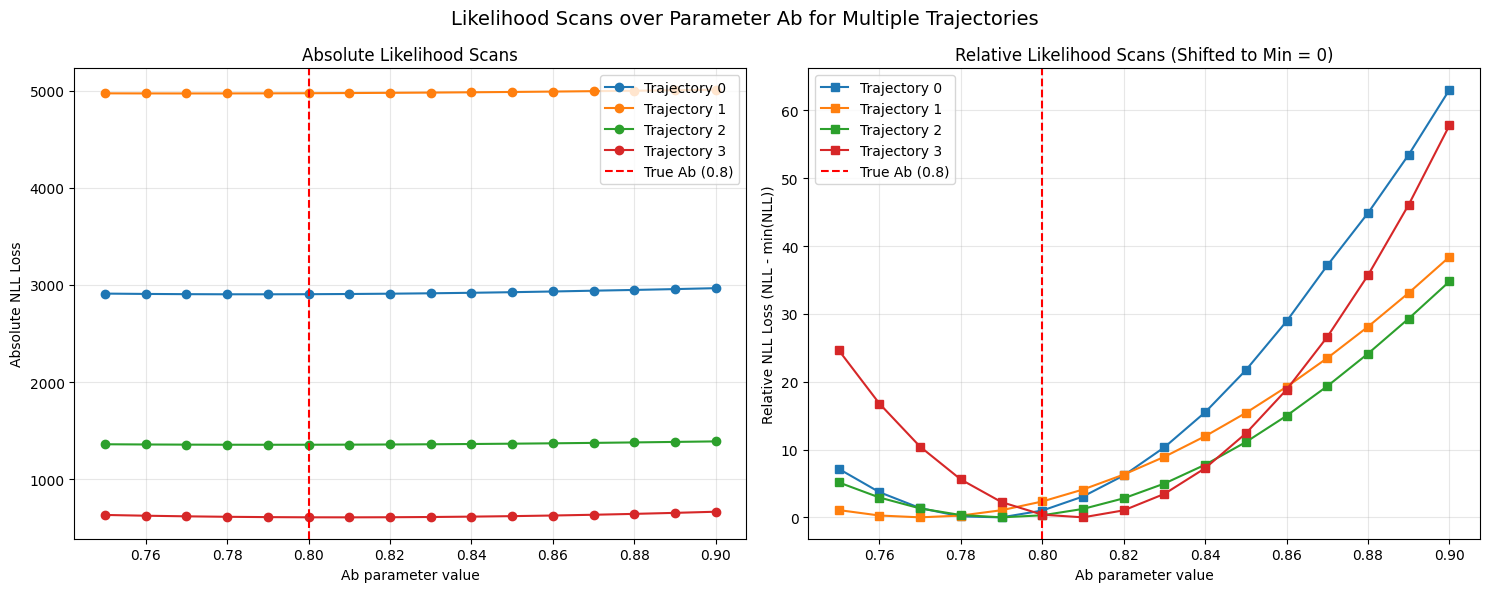

In [8]:
# Select a few individual trajectory indices for comparison (nominal is Ab = 0.8)
comparison_trajectories = [0, 1, 2, 3]

# Scan values for Ab
ab_scan_vals = np.linspace(0.75, 0.90, 16)

# Store results
nll_scans = {}

print(f"Starting Ab likelihood scans for individual trajectories {comparison_trajectories}...")

for traj_idx in comparison_trajectories:
    # 1. Load the trajectory segments using individual trajectory row indices
    rows = dataset.trajectory_row_indices[traj_idx]
    selected_struct = dataset.tracks_struct[rows]
    true_track_np = np_from_structured(selected_struct)
    
    # 2. Chop true track and generate stochastic target prediction at nominal Ab
    true_chopped, _ = chop_tracks(true_track_np, fields, precision=0.1)
    true_chopped_jax = jax.device_put(true_chopped)
    
    # Generate reference target predictions using true track and nominal parameters
    target_pred = sim_strategy.predict(current_params, true_chopped_jax, fields, rngkey=42)
    target_hits = {
        'pixel_id': target_pred['hit_pixels'],
        'ticks': target_pred['ticks'],
        'adcs': target_pred['adcs']
    }
    
    # 3. Create Option A straight-line guess (fixed dEdx = 1.887 MeV/cm)
    guess_track_np = make_straight_line_guess(true_track_np, fields, segment_length=10.0)
    guess_chopped, _ = chop_tracks(guess_track_np, fields, precision=0.1)
    
    # Set mean dEdx
    guess_mean_dedx_chopped = guess_chopped.copy()
    guess_mean_dedx_chopped[:, fields.index('dE')] = 1.887 * guess_mean_dedx_chopped[:, fields.index('dx')]
    if 'dEdx' in fields:
        guess_mean_dedx_chopped[:, fields.index('dEdx')] = 1.887
        
    guess_mean_dedx_chopped_jax = jax.device_put(guess_mean_dedx_chopped)
    
    # 4. Perform the parameter scan over Ab
    track_losses = []
    for ab_val in ab_scan_vals:
        p_eval = current_params.replace(Ab=ab_val)
        
        # Predict using Option A straight line
        pred = prob_strategy.predict(p_eval, guess_mean_dedx_chopped_jax, fields, rngkey=42)
        loss_val, _ = loss_strategy.compute(p_eval, pred, target_hits)
        track_losses.append(float(loss_val))
        
    nll_scans[traj_idx] = np.array(track_losses)
    print(f"  Trajectory {traj_idx}: Min loss found at Ab = {ab_scan_vals[np.argmin(track_losses)]:.4f}")

# Plotting the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left plot: Absolute NLL Loss
for traj_idx, losses in nll_scans.items():
    ax1.plot(ab_scan_vals, losses, marker='o', label=f'Trajectory {traj_idx}')
ax1.axvline(current_params.Ab, color='red', linestyle='--', label=f'True Ab ({current_params.Ab})')
ax1.set_xlabel('Ab parameter value')
ax1.set_ylabel('Absolute NLL Loss')
ax1.set_title('Absolute Likelihood Scans')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Right plot: Relative NLL Loss (subtracted by minimum of each track)
for traj_idx, losses in nll_scans.items():
    rel_losses = losses - losses.min()
    ax2.plot(ab_scan_vals, rel_losses, marker='s', label=f'Trajectory {traj_idx}')
ax2.axvline(current_params.Ab, color='red', linestyle='--', label=f'True Ab ({current_params.Ab})')
ax2.set_xlabel('Ab parameter value')
ax2.set_ylabel('Relative NLL Loss (NLL - min(NLL))')
ax2.set_title('Relative Likelihood Scans (Shifted to Min = 0)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('Likelihood Scans over Parameter Ab for Multiple Trajectories', fontsize=14)
plt.tight_layout()
plt.show()

## 5.2 Optimization Fit of Parameter Ab for Multiple Trajectories

To demonstrate parameter estimation under the straight-line approximation, we perform an actual 1D optimization (fit) of the recombination parameter `Ab` using gradient descent (Adam optimizer) for 5 trajectories (trajectories 0, 1, 2, 3, 4). 

We perturb the initial parameter value to `Ab = 0.70` (nominal is `0.80`) and trace the convergence path of `Ab` and the NLL loss over 30 iterations for each trajectory. Note that since `larnd-sim-jax` has dynamic shapes inside its JIT tracing (due to `jnp.unique` in the detsim phase), we execute the gradient calculation in JAX eager mode (without `jax.jit`).

Starting Ab optimization fit for trajectories [0, 1, 2, 3, 4]...


  0%|          | 1/200 [00:00<00:23,  8.31it/s]

100%|██████████| 200/200 [06:09<00:00,  1.85s/it]


  Trajectory 0: Fitted Ab = 0.7862 (True: 0.80)


100%|██████████| 200/200 [00:42<00:00,  4.76it/s]


  Trajectory 1: Fitted Ab = 0.7701 (True: 0.80)


... (2 outputs left out)

100%|██████████| 200/200 [00:23<00:00,  8.38it/s]


  Trajectory 3: Fitted Ab = 0.8077 (True: 0.80)


100%|██████████| 200/200 [00:23<00:00,  8.36it/s]


  Trajectory 4: Fitted Ab = 0.8200 (True: 0.80)


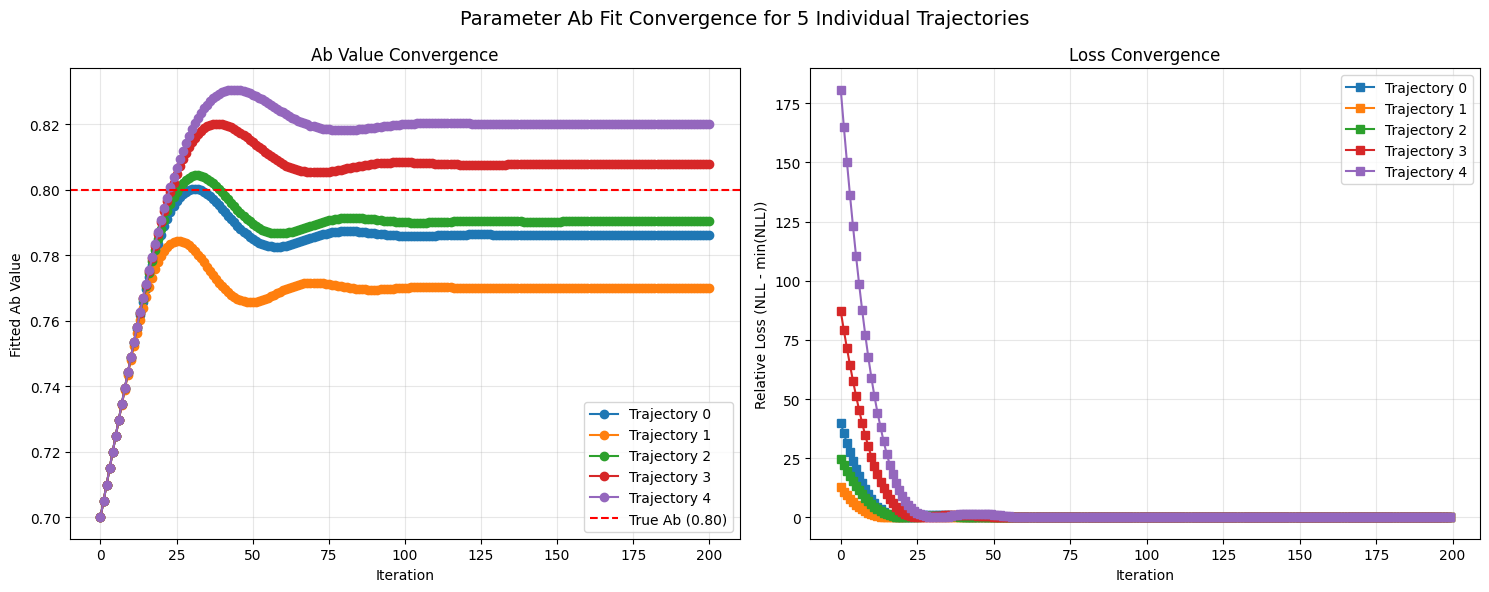

In [ ]:
import optax
import logging
from tqdm import tqdm
logging.getLogger('larndsim.sim_jax').setLevel(logging.WARNING)
# Select 5 trajectories to run the actual fit of Ab
fit_trajectories = [0, 1, 2, 3, 4]

# Optimization settings
init_Ab = 0.70
learning_rate = 0.005
steps = 200

# Store optimization paths
fit_results = {}

print(f"Starting Ab optimization fit for trajectories {fit_trajectories}...")

for traj_idx in fit_trajectories:
    # 1. Load trajectory and generate reference target hits
    rows = dataset.trajectory_row_indices[traj_idx]
    selected_struct = dataset.tracks_struct[rows]
    true_track_np = np_from_structured(selected_struct)
    
    true_chopped, _ = chop_tracks(true_track_np, fields, precision=0.1)
    true_chopped_jax = jax.device_put(true_chopped)
    
    target_pred = sim_strategy.predict(current_params, true_chopped_jax, fields, rngkey=42)
    target_hits = {
        'pixel_id': target_pred['hit_pixels'],
        'ticks': target_pred['ticks'],
        'adcs': target_pred['adcs']
    }
    
    # 2. Create Option A straight-line guess (fixed dEdx = 1.887 MeV/cm)
    guess_track_np = make_straight_line_guess(true_track_np, fields, segment_length=10.0)
    guess_chopped, _ = chop_tracks(guess_track_np, fields, precision=0.1)
    
    # Set mean dEdx
    guess_mean_dedx_chopped = guess_chopped.copy()
    guess_mean_dedx_chopped[:, fields.index('dE')] = 1.887 * guess_mean_dedx_chopped[:, fields.index('dx')]
    if 'dEdx' in fields:
        guess_mean_dedx_chopped[:, fields.index('dEdx')] = 1.887
    guess_mean_dedx_chopped_jax = jax.device_put(guess_mean_dedx_chopped)
    
    # 3. Define the NLL loss function as a function of Ab (in eager mode)
    def loss_fn(ab_val):
        p_eval = current_params.replace(Ab=ab_val)
        pred = prob_strategy.predict(p_eval, guess_mean_dedx_chopped_jax, fields, rngkey=42)
        loss_val, _ = loss_strategy.compute(p_eval, pred, target_hits)
        return loss_val
        
    grad_fn = jax.value_and_grad(loss_fn)
    
    # 4. Initialize optimizer
    ab_val = init_Ab
    optimizer = optax.adam(learning_rate=learning_rate)
    opt_state = optimizer.init(ab_val)
    
    ab_history = [float(ab_val)]
    loss_history = []
    
    # Run optimization loop
    for step in tqdm(range(steps)):
        loss_val, grad = grad_fn(ab_val)
        updates, opt_state = optimizer.update(grad, opt_state)
        ab_val = optax.apply_updates(ab_val, updates)
        
        ab_history.append(float(ab_val))
        loss_history.append(float(loss_val))
        
    print(f"  Trajectory {traj_idx}: Fitted Ab = {ab_val:.4f} (True: 0.80)")
    fit_results[traj_idx] = {'ab': ab_history, 'loss': loss_history}

# Plot the convergence histories
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left plot: Ab value vs iteration
for traj_idx, res in fit_results.items():
    ax1.plot(res['ab'], marker='o', label=f'Trajectory {traj_idx}')
ax1.axhline(0.80, color='red', linestyle='--', label='True Ab (0.80)')
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Fitted Ab Value')
ax1.set_title('Ab Value Convergence')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Right plot: Loss relative to final value vs iteration
for traj_idx, res in fit_results.items():
    losses = np.array(res['loss'])
    # Plot loss relative to minimum observed loss during the optimization
    rel_loss = losses - losses.min()
    ax2.plot(rel_loss, marker='s', label=f'Trajectory {traj_idx}')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('Relative Loss (NLL - min(NLL))')
ax2.set_title('Loss Convergence')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('Parameter Ab Fit Convergence for 5 Individual Trajectories', fontsize=14)
plt.tight_layout()
plt.show()

In [19]:
current_params.kb

0.0486

## 5.3 Realistic Calibration: Joint Fit of Calibration Parameter (e.g., Ab) and Track dE/dx

In a realistic calibration scenario, we do not know the exact energy deposition ($dE/dx$) profile of the muon tracks beforehand. Therefore, we must fit the calibration parameter (which is shared globally across all tracks) and the segment-by-segment `dEdx` values (which are track-specific parameters) **jointly**.

Here, we:
1. Select a batch of 3 trajectories (trajectories 0, 1, 2) to fit together, which helps average out stochastic fluctuations and noise.
2. Approximate each track as a straight line with segments of typical size to the input data ($\sim 1 \text{ cm}$).
3. Define a joint NLL loss function that sums the individual track losses.
4. Run a joint gradient descent loop (using `optax.adam`) to fit a global calibration parameter (e.g. `Ab`, perturbed to `0.70`) and all track segment `dEdx` values simultaneously. You can change `fit_param_name` in the code cell below to optimize other parameters such as `kb` or `lifetime`.

Starting joint fit of lifetime and dEdx for 8 trajectories...
  Step  0: Loss = 30345.35, lifetime = 501.0000 (grad_lifetime = -2.62)
  Step  5: Loss = 30305.54, lifetime = 505.9937 (grad_lifetime = -2.49)
  Step 10: Loss = 30228.97, lifetime = 510.9534 (grad_lifetime = -2.32)
  Step 15: Loss = 30169.10, lifetime = 515.8553 (grad_lifetime = -2.21)
  Step 20: Loss = 30118.34, lifetime = 520.6902 (grad_lifetime = -2.09)
  Step 25: Loss = 30077.20, lifetime = 525.4268 (grad_lifetime = -1.96)
  Step 30: Loss = 30046.24, lifetime = 530.0393 (grad_lifetime = -1.81)
  Step 35: Loss = 30022.08, lifetime = 534.5038 (grad_lifetime = -1.69)
  Step 40: Loss = 30002.65, lifetime = 538.8127 (grad_lifetime = -1.57)
  Step 45: Loss = 29986.51, lifetime = 542.9635 (grad_lifetime = -1.48)
  Step 50: Loss = 29972.96, lifetime = 546.9648 (grad_lifetime = -1.40)
  Step 55: Loss = 29961.46, lifetime = 550.8287 (grad_lifetime = -1.33)
  Step 60: Loss = 29951.65, lifetime = 554.5699 (grad_lifetime = -1.27)
  

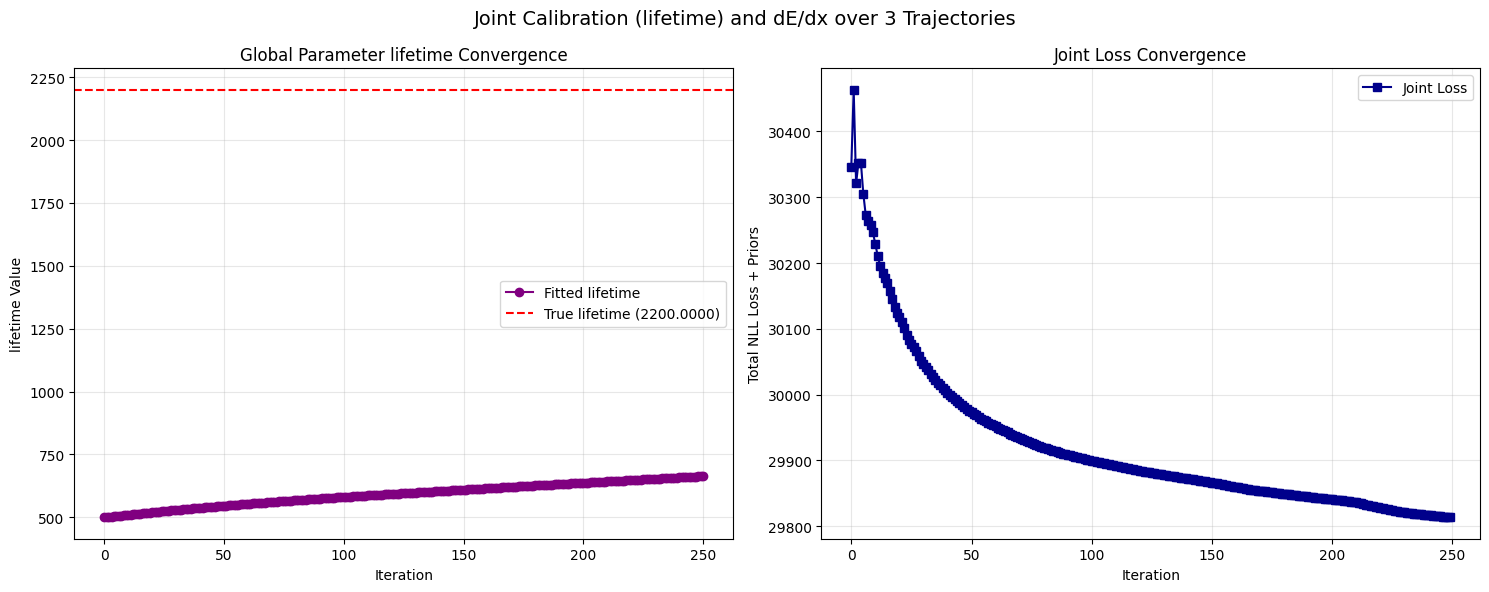

In [29]:
from tqdm import tqdm

# 1. Select a batch of 3 trajectories for joint calibration
fit_trajectories = [0, 1, 2, 3, 4, 5, 6, 7]

# Choose which calibration parameter to fit (from RELEVANT_PARAMS)
# E.g. 'Ab' (true: 0.8), 'kb' (true: 0.01) or others in ranges
fit_param_name = 'lifetime'
init_param_val = 500.  # Perturbed starting value

# Optimization settings
lr_param = 1
lr_dedx = 0.01
steps = 250

# 2. Load trajectories, chop, and generate reference target hits
guess_opt_list = []
parent_ids_list = []
target_hits_list = []
init_log_dedx_list = []

for traj_idx in fit_trajectories:
    # Load trajectory segments
    rows = dataset.trajectory_row_indices[traj_idx]
    selected_struct = dataset.tracks_struct[rows]
    true_track_np = np_from_structured(selected_struct)
    
    # Generate reference target from true track
    true_chopped, _ = chop_tracks(true_track_np, fields, precision=current_params.electron_sampling_resolution)
    true_chopped_jax = jax.device_put(true_chopped)
    
    target_pred = sim_strategy.predict(current_params, true_chopped_jax, fields, rngkey=42)
    target_hits = {
        'pixel_id': target_pred['hit_pixels'],
        'ticks': target_pred['ticks'],
        'adcs': target_pred['adcs']
    }
    target_hits_list.append(target_hits)
    
    # Create 1.0 cm straight-line guess segments (similar to input segment size)
    guess_track_np = make_straight_line_guess(true_track_np, fields, segment_length=1.0)
    guess_chopped, parent_ids = chop_tracks(guess_track_np, fields, precision=current_params.electron_sampling_resolution)
    
    guess_opt_list.append(jax.device_put(guess_chopped))
    parent_ids_list.append(jax.device_put(jnp.asarray(parent_ids, dtype=jnp.int32)))
    
    n_segs = guess_track_np.shape[0]
    init_log_dedx_list.append(jnp.log(jnp.full((n_segs,), 1.887)))

# 3. Define the joint NLL loss function
def total_loss_fn(param_val, log_dedx_list):
    total_loss = 0.0
    for k in range(len(fit_trajectories)):
        guess_opt_jax = guess_opt_list[k]
        parent_ids_jax = parent_ids_list[k]
        target_hits = target_hits_list[k]
        log_dedx_val = log_dedx_list[k]
        
        # Build parameter evaluation dictionary dynamically
        replace_kwargs = {fit_param_name: param_val}
        p_eval = current_params.replace(**replace_kwargs)
        
        # Map parent segment dEdx values to chopped sub-segments
        dedx_idx = fields.index('dEdx')
        dE_idx   = fields.index('dE')
        dx_idx   = fields.index('dx')
        
        valid_mask = (parent_ids_jax >= 0)
        safe_ids = jnp.clip(parent_ids_jax, 0, log_dedx_val.shape[0] - 1)
        dedx_fitted = jnp.maximum(jnp.exp(jnp.take(log_dedx_val, safe_ids)), 1e-3)
        dedx_sample = jnp.where(valid_mask, dedx_fitted, guess_opt_jax[:, dedx_idx])
        
        t = guess_opt_jax.at[:, dedx_idx].set(dedx_sample)
        t = t.at[:, dE_idx].set(dedx_sample * t[:, dx_idx])
        
        # Predict pixel charge/time distributions
        pred = prob_strategy.predict(p_eval, t, fields, rngkey=42)
        hit_loss, _ = loss_strategy.compute(p_eval, pred, target_hits)
        
        # Prior constraint on dEdx (split Student-t prior centered at 1.887 MeV/cm)
        dedx_prior = split_student_t_nll(
            dedx_sample,
            DEDX_SPLIT_NU_L,
            DEDX_SPLIT_NU_R,
            1.887,
            DEDX_SPLIT_SCALE_L,
            DEDX_SPLIT_SCALE_R,
            weights=t[:, dx_idx]
        ) * 0.5
        
        # Mean constraint (preventing overall scale drift of the dEdx parameters)
        mean_constraint = 100000.0 * (jnp.mean(dedx_fitted) - 1.887)**2
        
        total_loss += (hit_loss + dedx_prior + mean_constraint)
        
    return total_loss

# 4. Joint fit optimization loop
grad_fn = jax.value_and_grad(total_loss_fn, argnums=(0, 1))

param_val = init_param_val
log_dedx_list = [jnp.copy(x) for x in init_log_dedx_list]

# Separate Adam optimizers for the global parameter and local dEdx parameters
opt_param = optax.adam(learning_rate=lr_param)
opt_state_param = opt_param.init(param_val)

opt_dedx = optax.adam(learning_rate=lr_dedx)
opt_state_dedx = opt_dedx.init(log_dedx_list)

param_history = [float(param_val)]
loss_history = []

print(f"Starting joint fit of {fit_param_name} and dEdx for {len(fit_trajectories)} trajectories...")

for step in range(steps):
    loss_val, (grad_param, grad_dedx_list) = grad_fn(param_val, log_dedx_list)
    
    # Update global parameter
    updates_param, opt_state_param = opt_param.update(grad_param, opt_state_param)
    param_val = optax.apply_updates(param_val, updates_param)
    
    # Update local dEdx values
    updates_dedx, opt_state_dedx = opt_dedx.update(grad_dedx_list, opt_state_dedx)
    log_dedx_list = optax.apply_updates(log_dedx_list, updates_dedx)
    
    param_history.append(float(param_val))
    loss_history.append(float(loss_val))
    
    if step % 5 == 0 or step == steps - 1:
        print(f"  Step {step:2d}: Loss = {loss_val:.2f}, {fit_param_name} = {param_val:.4f} (grad_{fit_param_name} = {grad_param:.2f})")

true_val = float(getattr(current_params, fit_param_name))
print(f"Joint fit completed. Final {fit_param_name} = {param_val:.4f} (True: {true_val:.4f})")

# 5. Plot the joint calibration convergence path
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Parameter convergence plot
ax1.plot(param_history, marker='o', color='purple', label=f'Fitted {fit_param_name}')
ax1.axhline(true_val, color='red', linestyle='--', label=f'True {fit_param_name} ({true_val:.4f})')
ax1.set_xlabel('Iteration')
ax1.set_ylabel(f'{fit_param_name} Value')
ax1.set_title(f'Global Parameter {fit_param_name} Convergence')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Loss convergence plot
ax2.plot(loss_history, marker='s', color='darkblue', label='Joint Loss')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('Total NLL Loss + Priors')
ax2.set_title('Joint Loss Convergence')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle(f'Joint Calibration ({fit_param_name}) and dE/dx over 3 Trajectories', fontsize=14)
plt.tight_layout()
plt.show()

## 6. Test 1D Optimization Fit: Option A (Fixed dEdx)

We run a short gradient descent fit on `shift_x` using JAX `value_and_grad` with $dE/dx$ fixed at `1.887 MeV/cm`.

In [ ]:
import optax

guess_jax = jax.device_put(guess_mean_dedx_chopped)
init_shift_x = current_params.shift_x + 1.0
x_val = init_shift_x

def loss_and_grad_fn_optA(shift_x_val):
    p_eval = current_params.replace(shift_x=shift_x_val)
    pred = prob_strategy.predict(p_eval, guess_jax, fields, rngkey=42)
    loss_val, _ = loss_strategy.compute(p_eval, pred, target)
    return loss_val

grad_fn_optA = jax.value_and_grad(loss_and_grad_fn_optA)

optimizer = optax.adam(learning_rate=0.05)
opt_state = optimizer.init(x_val)

history_x_optA = [float(x_val)]
history_loss_optA = []

print('Starting 1D fit on shift_x (Option A)...')
for step in range(50):
    loss_val, grad = grad_fn_optA(x_val)
    updates, opt_state = optimizer.update(grad, opt_state)
    x_val = optax.apply_updates(x_val, updates)
    
    history_x_optA.append(float(x_val))
    history_loss_optA.append(float(loss_val))
    
    if step % 5 == 0:
        print(f'  Step {step:2d}: shift_x={x_val:.4f} (True: {current_params.shift_x:.4f}), Loss={loss_val:.2f}, Grad={grad:.2f}')

print(f'Final shift_x (Option A): {x_val:.4f} (True: {current_params.shift_x:.4f})')

## 7. Test 1D Optimization Fit: Option B (Phased/Iterative dEdx)

We run the phased iterative optimization fit on `shift_x` and the per-segment $dE/dx$ values:
1. **Warm-up phase (steps 0-20):** `shift_x` is optimized while `dEdx` is kept fixed at the initial guess of `1.887 MeV/cm`.
2. **Joint fit phase (steps 20-50):** Both `shift_x` and `dEdx` are optimized jointly.
3. **Fine-tuning phase (steps 50-80):** `dEdx` is frozen at the fitted values, and only `shift_x` is optimized.

In [ ]:
guess_optB_jax = jax.device_put(guess_chopped)
parent_ids_jax = jax.device_put(jnp.asarray(parent_ids, dtype=jnp.int32))
n_segs = guess_track_np.shape[0]

# Initial log_dedx set to log(1.887)
init_log_dedx = jnp.log(jnp.full((n_segs,), 1.887))

def loss_and_grad_fn_optB(shift_x_val, log_dedx_val):
    p_eval = current_params.replace(shift_x=shift_x_val)
    
    dedx_idx = fields.index('dEdx')
    dE_idx   = fields.index('dE')
    dx_idx   = fields.index('dx')
    
    valid_mask = (parent_ids_jax >= 0)
    safe_ids = jnp.clip(parent_ids_jax, 0, log_dedx_val.shape[0] - 1)
    dedx_fitted = jnp.maximum(jnp.exp(jnp.take(log_dedx_val, safe_ids)), 1e-3)
    dedx_sample = jnp.where(valid_mask, dedx_fitted, guess_optB_jax[:, dedx_idx])
    
    t = guess_optB_jax.at[:, dedx_idx].set(dedx_sample)
    t = t.at[:, dE_idx].set(dedx_sample * t[:, dx_idx])
    
    pred = prob_strategy.predict(p_eval, t, fields, rngkey=42)
    hit_loss, _ = loss_strategy.compute(p_eval, pred, target)
    
    # Prior NLL on dEdx
    dedx_prior = split_student_t_nll(
        dedx_sample,
        DEDX_SPLIT_NU_L,
        DEDX_SPLIT_NU_R,
        1.887, # loc
        DEDX_SPLIT_SCALE_L,
        DEDX_SPLIT_SCALE_R,
        weights=t[:, dx_idx]
    ) * 0.5
    
    # Mean constraint
    mean_constraint = 100000.0 * (jnp.mean(dedx_fitted) - 1.887)**2
    
    return hit_loss + dedx_prior + mean_constraint

grad_fn_optB = jax.value_and_grad(loss_and_grad_fn_optB, argnums=(0, 1))

x_val = init_shift_x
log_dedx_val = init_log_dedx

# Create separate Adam optimizers for global param and dEdx (different learning rates)
opt_x = optax.adam(learning_rate=0.05)
opt_state_x = opt_x.init(x_val)

opt_dedx = optax.adam(learning_rate=0.01)
opt_state_dedx = opt_dedx.init(log_dedx_val)

history_x_optB = [float(x_val)]
history_loss_optB = []

# Iterative/Phased fitting configuration
dedx_start_iter = 20
dedx_freeze_iter = 50
total_steps = 80

print(f'Starting iterative 1D fit on shift_x (Option B)...')
print(f'  Warm-up: steps 0-{dedx_start_iter} (dEdx fixed)')
print(f'  Joint fit: steps {dedx_start_iter}-{dedx_freeze_iter} (dEdx active)')
print(f'  Fine-tune: steps {dedx_freeze_iter}-{total_steps} (dEdx frozen)')

for step in range(total_steps):
    loss_val, (grad_x, grad_dedx) = grad_fn_optB(x_val, log_dedx_val)
    
    # Check phases
    dedx_active = (step >= dedx_start_iter) and (step < dedx_freeze_iter)
    
    # Reset optimizer state at transitions to mimic the real training setup
    if step == dedx_start_iter:
        print(f'  [Step {step}]: dEdx activated -> resetting shift_x optimizer state')
        opt_state_x = opt_x.init(x_val)
    elif step == dedx_freeze_iter:
        print(f'  [Step {step}]: dEdx frozen -> resetting shift_x optimizer state')
        opt_state_x = opt_x.init(x_val)
        
    # Update shift_x (always active)
    updates_x, opt_state_x = opt_x.update(grad_x, opt_state_x)
    x_val = optax.apply_updates(x_val, updates_x)
    
    # Update log_dedx (only when active)
    if dedx_active:
        updates_dedx, opt_state_dedx = opt_dedx.update(grad_dedx, opt_state_dedx)
        log_dedx_val = optax.apply_updates(log_dedx_val, updates_dedx)
        
    history_x_optB.append(float(x_val))
    history_loss_optB.append(float(loss_val))
    
    if step % 5 == 0 or step == total_steps - 1:
        mean_fitted_dedx = float(jnp.mean(jnp.exp(log_dedx_val)))
        status = "Fixed" if step < dedx_start_iter else ("Frozen" if step >= dedx_freeze_iter else "Active")
        print(f'  Step {step:2d} ({status:6s}): shift_x={x_val:.4f} (True: {current_params.shift_x:.4f}), Mean dEdx={mean_fitted_dedx:.4f}, Loss={loss_val:.2f}, Grad_x={grad_x:.2f}')

print(f'Final shift_x (Option B): {x_val:.4f} (True: {current_params.shift_x:.4f})')
print('Final per-segment fitted dEdx:', np.exp(np.array(log_dedx_val)))

## 8. Convergence Comparison

We plot parameter convergence and loss convergence side-by-side.

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history_x_optA, marker='o', label='Option A: Fixed dEdx')
ax1.plot(history_x_optB, marker='s', label='Option B: Fitted dEdx')
ax1.axhline(current_params.shift_x, color='red', linestyle='--', label='True Value')
ax1.set_xlabel('Iteration')
ax1.set_ylabel('shift_x value [cm]')
ax1.set_title('Parameter convergence comparison')
ax1.legend()
ax1.grid(True)

ax2.plot(history_loss_optA, marker='o', label='Option A: Fixed dEdx')
ax2.plot(history_loss_optB, marker='s', label='Option B: Fitted dEdx')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('Loss (NLL + priors)')
ax2.set_title('Loss convergence comparison')
ax2.legend()
ax2.grid(True)

plt.show()

## 9. Geometric Deviation Analysis of Straight-Line Approximation over all Tracks

To quantify the systematic geometric error introduced by approximating stochastic muon trajectories as simple straight lines between their start and endpoints, we compute the perpendicular distance from each point along the true trajectory to the straight-line segment. We do this for all muon tracks in the dataset without executing detector simulations or fitting parameters, allowing us to evaluate the full spatial bias profile quickly.

Analyzing straight-line approximation over all 57890 tracks...
Done.

Straight-Line Approximation Deviation Summary (57890 tracks):
  Mean of Mean Deviations: 13.9415 cm (Max: 90.4021 cm)
  Mean of Max Deviations:  36.8427 cm (Max: 136.7305 cm)
  Mean of RMSE Deviations: 19.1656 cm (Max: 106.6681 cm)


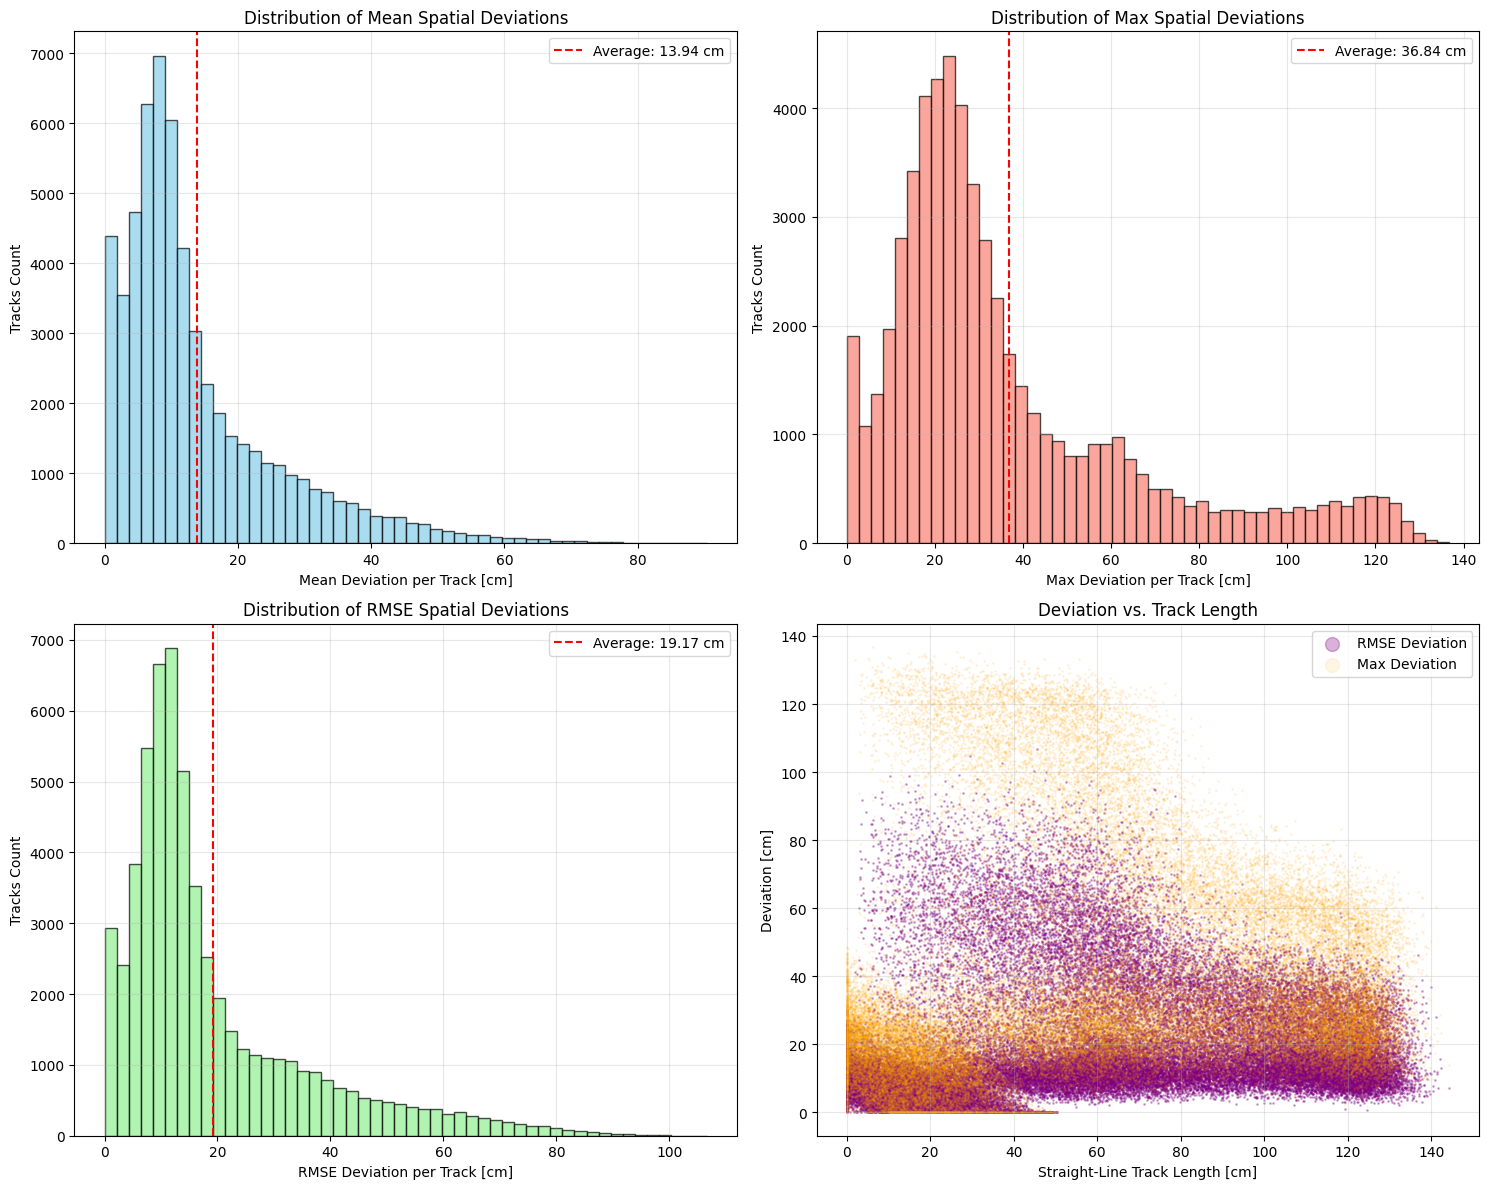

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate the spatial deviation (perpendicular distance to the straight line segment)
# and oriented deviations (dx, dy, dz) for all individual trajectories in the dataset.
means = []
maxes = []
rmses = []
lengths = []

dx_list = []
dy_list = []
dz_list = []

print(f"Analyzing straight-line approximation over all {len(dataset.trajectory_row_indices)} tracks...")

for t in range(len(dataset.trajectory_row_indices)):
    rows = dataset.trajectory_row_indices[t]
    selected_struct = dataset.tracks_struct[rows]
    
    # Extract all starts and ends points of the segments
    starts = np.stack([selected_struct['x_start'], selected_struct['y_start'], selected_struct['z_start']], axis=-1)
    ends = np.stack([selected_struct['x_end'], selected_struct['y_end'], selected_struct['z_end']], axis=-1)
    pts = np.concatenate([starts, ends], axis=0)
    
    # Identify the track's endpoints by finding the furthest pair of points
    dists = np.linalg.norm(pts[:, None, :] - pts[None, :, :], axis=-1)
    i, j = np.unravel_index(np.argmax(dists), dists.shape)
    start_pos = pts[i]
    end_pos = pts[j]
    length = dists[i, j]
    lengths.append(length)
    
    # Calculate perpendicular distance from all points on the track to the straight line segment
    v = end_pos - start_pos
    v_lensq = np.dot(v, v)
    if v_lensq < 1e-10:
        closest_pts = np.repeat(start_pos[None, :], len(pts), axis=0)
        deviations = np.linalg.norm(pts - start_pos, axis=1)
    else:
        proj = np.dot(pts - start_pos, v) / v_lensq
        proj = np.clip(proj, 0.0, 1.0)
        closest_pts = start_pos + proj[:, None] * v
        deviations = np.linalg.norm(pts - closest_pts, axis=1)
        
    means.append(deviations.mean())
    maxes.append(deviations.max())
    rmses.append(np.sqrt((deviations**2).mean()))
    
    # Collect oriented deviations
    diff = pts - closest_pts
    dx_list.append(diff[:, 0])
    dy_list.append(diff[:, 1])
    dz_list.append(diff[:, 2])

means = np.array(means)
maxes = np.array(maxes)
rmses = np.array(rmses)
lengths = np.array(lengths)

dx = np.concatenate(dx_list)
dy = np.concatenate(dy_list)
dz = np.concatenate(dz_list)

print("Done.")

# Summary statistics
print(f"\nStraight-Line Approximation Deviation Summary ({len(means)} tracks, {len(dx)} points):")
print(f"  Mean of Mean Deviations: {means.mean():.4f} cm ({means.mean()*10:.4f} mm)")
print(f"  Mean of Max Deviations:  {maxes.mean():.4f} cm ({maxes.mean()*10:.4f} mm)")
print(f"  Mean of RMSE Deviations: {rmses.mean():.4f} cm ({rmses.mean()*10:.4f} mm)")
print(f"\nOriented Segment Deviations:")
print(f"  dx: mean = {dx.mean()*10:.4f} mm, std = {dx.std()*10:.4f} mm")
print(f"  dy: mean = {dy.mean()*10:.4f} mm, std = {dy.std()*10:.4f} mm")
print(f"  dz: mean = {dz.mean()*10:.4f} mm, std = {dz.std()*10:.4f} mm")

# Plot 1: Absolute deviation distributions and scatter plot
fig, axs = plt.subplots(2, 2, figsize=(15, 12))

# 1. Distribution of Mean Deviations
axs[0, 0].hist(means * 10, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axs[0, 0].axvline(means.mean() * 10, color='red', linestyle='--', label=f'Average: {means.mean() * 10:.2f} mm')
axs[0, 0].set_xlabel('Mean Deviation per Track [mm]')
axs[0, 0].set_ylabel('Tracks Count')
axs[0, 0].set_title('Distribution of Mean Spatial Deviations')
axs[0, 0].legend()
axs[0, 0].grid(True, alpha=0.3)

# 2. Distribution of Max Deviations
axs[0, 1].hist(maxes * 10, bins=50, color='salmon', edgecolor='black', alpha=0.7)
axs[0, 1].axvline(maxes.mean() * 10, color='red', linestyle='--', label=f'Average: {maxes.mean() * 10:.2f} mm')
axs[0, 1].set_xlabel('Max Deviation per Track [mm]')
axs[0, 1].set_ylabel('Tracks Count')
axs[0, 1].set_title('Distribution of Max Spatial Deviations')
axs[0, 1].legend()
axs[0, 1].grid(True, alpha=0.3)

# 3. Distribution of RMSE Deviations
axs[1, 0].hist(rmses * 10, bins=50, color='lightgreen', edgecolor='black', alpha=0.7)
axs[1, 0].axvline(rmses.mean() * 10, color='red', linestyle='--', label=f'Average: {rmses.mean() * 10:.2f} mm')
axs[1, 0].set_xlabel('RMSE Deviation per Track [mm]')
axs[1, 0].set_ylabel('Tracks Count')
axs[1, 0].set_title('Distribution of RMSE Spatial Deviations')
axs[1, 0].legend()
axs[1, 0].grid(True, alpha=0.3)

# 4. Deviation vs Track Length
axs[1, 1].scatter(lengths, rmses * 10, s=1, color='purple', alpha=0.3, label='RMSE Deviation')
axs[1, 1].scatter(lengths, maxes * 10, s=1, color='orange', alpha=0.1, label='Max Deviation')
axs[1, 1].set_xlabel('Straight-Line Track Length [cm]')
axs[1, 1].set_ylabel('Deviation [mm]')
axs[1, 1].set_title('Deviation vs. Track Length')
axs[1, 1].legend(markerscale=10)
axs[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot 2: Oriented deviations in x, y, z (expressed in mm)
fig2, axs2 = plt.subplots(1, 3, figsize=(18, 5))
titles = ['X Oriented Deviation (dx)', 'Y Oriented Deviation (dy)', 'Z Oriented Deviation (dz)']
data = [dx * 10, dy * 10, dz * 10]
colors = ['lightskyblue', 'lightcoral', 'palegreen']

for i in range(3):
    d_comp = data[i]
    mu = d_comp.mean()
    std = d_comp.std()
    
    # Plot normalized histogram
    n, bins, patches = axs2[i].hist(d_comp, bins=100, density=True, color=colors[i], edgecolor='black', alpha=0.6, label='Data')
    
    # Overlay Gaussian fit
    xmin, xmax = axs2[i].get_xlim()
    x_fit = np.linspace(xmin, xmax, 200)
    p_fit = 1 / (std * np.sqrt(2 * np.pi)) * np.exp(-((x_fit - mu) ** 2) / (2 * std ** 2))
    axs2[i].plot(x_fit, p_fit, 'r-', linewidth=2, label=f'Gaussian Fit\n$\mu$={mu:.3f} mm\n$\sigma$={std:.3f} mm')
    
    axs2[i].set_xlabel('Deviation [mm]')
    axs2[i].set_ylabel('Probability Density')
    axs2[i].set_title(titles[i])
    axs2[i].legend()
    axs2[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Track Position Fitting & Profiling Toy Study

We will implement a toy study where we fit a global calibration parameter (e.g., `Ab`, nominal: 0.8) and the track's local translation and rotation (geometry alignment) jointly or alternately. Since local geometry alignment is highly non-convex and sensitive to local minima, we compare:
- **Scenario A: Global Param Fit (Without Alignment)**: Fit `Ab` while keeping the guess track at its unaligned straight-line position.
- **Scenario B: Joint Fit (Calibration + Track Alignment)**: Fit `Ab` and the track translation/rotation variables simultaneously in JAX using `optax.adam`.
- **Scenario C: Alternating Fit (Calibration + Track Alignment Profiling)**: Fit `Ab` globally with Optax, but profile (align) the track positions locally at each step using `scipy.optimize.minimize(method='L-BFGS-B')`.

In [9]:
import optax
from scipy.optimize import minimize
from optimize.fit_params import apply_transformation, simulate_wfs_static
from larndsim.sim_jax import simulate_probabilistic, simulate_wfs, pad_to_closest_multiple

# 1. Setup initial parameters and perturbed values
init_Ab = 0.70
true_Ab = 0.80
steps = 100

# Start all scenarios from zero geometry (= best straight-line fit guess)
init_translation = np.zeros(3, dtype=np.float32)
init_rotation = np.zeros(3, dtype=np.float32)

guess_mean_dedx_chopped = guess_chopped.copy()
guess_mean_dedx_chopped[:, fields.index('dE')] = 1.887 * guess_mean_dedx_chopped[:, fields.index('dx')]
if 'dEdx' in fields:
    guess_mean_dedx_chopped[:, fields.index('dEdx')] = 1.887
guess_mean_dedx_chopped_jax = jax.device_put(guess_mean_dedx_chopped)

# 2. Precompute static pixels list for the guess and target tracks to enable JIT compilation
print("Precomputing static pixel lists...")
true_chopped_jax = jax.device_put(true_chopped)
wfs_true, true_pixels = simulate_wfs(current_params, response, true_chopped_jax, fields)
wfs_guess, guess_pixels = simulate_wfs(current_params, response, guess_mean_dedx_chopped_jax, fields)

# Combine active pixels to build a static pixel list
combined_pixels = np.unique(np.concatenate([np.array(true_pixels[true_pixels >= 0]), np.array(guess_pixels[guess_pixels >= 0])]))
combined_pixels = np.append(combined_pixels, -1)
padded_len = int(((len(combined_pixels) + 127) // 128) * 128)
fixed_pixels_np = pad_to_closest_multiple(combined_pixels, multiple=padded_len, pad_value=-1, pad_front=False)
fixed_pixels_np = np.sort(fixed_pixels_np)
fixed_pixels = jnp.array(fixed_pixels_np)

print(f"Global static pixels padded to: {padded_len}")

# 3. Define predict_static using the precomputed fixed_pixels list
# This function is designed to be JIT-compatible: fixed_pixels has a static shape.
def predict_static(params_eval, tracks_eval):
    wfs = simulate_wfs_static(params_eval, response, tracks_eval, fields, fixed_pixels)
    wfs_padded = pad_to_closest_multiple(wfs, dims_to_pad=(0,), multiple=128, pad_value=0.0, pad_front=True)
    adcs_distrib, pixel_x, pixel_y, ticks_prob, event = simulate_probabilistic(
        params_eval, wfs_padded, fixed_pixels
    )
    return {
        'adcs_distrib': adcs_distrib,
        'hit_prob': ticks_prob,
        'pixel_x': pixel_x,
        'pixel_y': pixel_y,
        'unique_pixels': fixed_pixels,
        'event': event
    }

# 4. Define core differentiable loss (takes ab_val and geom_vars both as JAX arrays)
# This is the single loss function JIT-traced once and shared across all scenarios.
def _core_loss(ab_val, geom_vars):
    """Compute NLL loss given Ab (scalar JAX) and 6D geometry vars (JAX array [tx,ty,tz,rx,ry,rz])."""
    translation = geom_vars[0:3]
    rotation = geom_vars[3:6] * 0.1
    transformed_track = apply_transformation(guess_mean_dedx_chopped_jax, fields, translation, rotation)
    p_eval = current_params.replace(Ab=ab_val)
    pred = predict_static(p_eval, transformed_track)
    loss_val, _ = loss_strategy.compute(p_eval, pred, target)
    return loss_val

# JIT-compile once: gradient w.r.t. both ab_val and geom_vars
_core_val_and_grad = jax.jit(jax.value_and_grad(_core_loss, argnums=(0, 1)))

# Initial geometry (zeros = straight-line fit, shared by all scenarios)
init_geom_vars = jnp.zeros(6, dtype=jnp.float32)

def loss_fn_A(ab_val):
    """Scenario A: no alignment — Ab is fitted but geometry is frozen at zero (straight-line guess)."""
    loss_val, _ = _core_val_and_grad(ab_val, init_geom_vars)
    return loss_val

def loss_fn_B(ab_val, geom_vars):
    """Scenario B: joint JAX fit — return loss only."""
    loss_val, _ = _core_val_and_grad(ab_val, geom_vars)
    return loss_val

# For Scenario A gradient
_grad_fn_A = jax.jit(jax.value_and_grad(loss_fn_A))

# For Scenario B gradient (w.r.t. both args)
def _grad_fn_B(ab_val, geom_vars):
    return _core_val_and_grad(ab_val, geom_vars)

# For Scenario C:
# local_geom_grad: grad of loss w.r.t. geom_vars only (ab_val is 'frozen' from outer loop)
_local_geom_val_and_grad = jax.jit(jax.value_and_grad(lambda gv, ab: _core_loss(ab, gv), argnums=0))

# ab_grad for global step in scenario C: grad w.r.t. ab_val only
_ab_val_and_grad = jax.jit(jax.value_and_grad(lambda ab, gv: _core_loss(ab, gv), argnums=0))

print("All loss functions and JIT-compiled gradients initialized.")


INFO:larndsim.sim_jax:Padding from shape (92,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (93,) to target shape (128,) with pad value -1


Precomputing static pixel lists...


/sdf/group/neutrino/pgranger/larnd-sim-jax/src/larndsim/sim_jax.py:37: UserWarning: Explicitly requested dtype int64 requested in full is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  buffer = jnp.full(target_shape, pad_value, dtype=x.dtype)


Global static pixels padded to: 128
All loss functions and JIT-compiled gradients initialized.


In [10]:
# --- SCENARIO A: Global Param Fit only (No Alignment) ---
def run_fit_A(steps=100, lr=0.005):
    ab_val = jnp.array(init_Ab)
    optimizer = optax.adam(learning_rate=lr)
    opt_state = optimizer.init(ab_val)

    history_ab = [float(ab_val)]
    history_loss = []

    print("Running Scenario A (No Alignment)...")
    for step in range(steps):
        loss_val, grad = _grad_fn_A(ab_val)
        updates, opt_state = optimizer.update(grad, opt_state)
        ab_val = optax.apply_updates(ab_val, updates)
        history_ab.append(float(ab_val))
        history_loss.append(float(loss_val))
        if step % 10 == 0 or step == steps - 1:
            print(f"  Step {step:3d}: Ab = {float(ab_val):.4f} (True: {true_Ab:.2f}), Loss = {float(loss_val):.4f}")
    return history_ab, history_loss


# --- SCENARIO B: Joint Fit in JAX (Calibration + Alignment via Optax) ---
def run_fit_B(steps=100, lr_ab=0.005, lr_geom=0.01):
    ab_val = jnp.array(init_Ab)
    geom_vars = jnp.array(init_geom_vars)

    optimizer_ab = optax.adam(learning_rate=lr_ab)
    opt_state_ab = optimizer_ab.init(ab_val)
    optimizer_geom = optax.adam(learning_rate=lr_geom)
    opt_state_geom = optimizer_geom.init(geom_vars)

    history_ab = [float(ab_val)]
    history_geom = [np.array(geom_vars)]
    history_loss = []

    print("Running Scenario B (Joint JAX Fit)...")
    for step in range(steps):
        loss_val, (grad_ab, grad_geom) = _grad_fn_B(ab_val, geom_vars)

        updates_ab, opt_state_ab = optimizer_ab.update(grad_ab, opt_state_ab)
        ab_val = optax.apply_updates(ab_val, updates_ab)

        updates_geom, opt_state_geom = optimizer_geom.update(grad_geom, opt_state_geom)
        geom_vars = optax.apply_updates(geom_vars, updates_geom)

        history_ab.append(float(ab_val))
        history_geom.append(np.array(geom_vars))
        history_loss.append(float(loss_val))
        if step % 10 == 0 or step == steps - 1:
            print(f"  Step {step:3d}: Ab = {float(ab_val):.4f} (True: {true_Ab:.2f}), "
                  f"Translation = {np.array(geom_vars[0:3])}, Loss = {float(loss_val):.4f}")
    return history_ab, history_geom, history_loss


# --- SCENARIO C: Alternating Fit ---
# Outer loop: Adam on Ab (JAX).
# Inner loop: L-BFGS-B on 6D geometry (SciPy), using the JIT-compiled gradient.
#
# KEY: ab_val is passed as a JAX array argument into the JIT'd gradient (not closed over),
# so JAX compiles once and reuses the XLA executable on every scipy iteration.
def run_fit_C(steps=100, lr_ab=0.005, track_max_iter=10):
    ab_val = jnp.array(init_Ab)
    geom_vars_np = np.array(init_geom_vars, dtype=np.float64)

    optimizer_ab = optax.adam(learning_rate=lr_ab)
    opt_state_ab = optimizer_ab.init(ab_val)

    history_ab = [float(ab_val)]
    history_geom = [geom_vars_np.copy()]
    history_loss = []

    print("Running Scenario C (Alternating: Adam on Ab + L-BFGS-B on Geometry)...")
    for step in range(steps):
        # --- Inner step: optimize geometry for current Ab ---
        ab_val_fixed = ab_val  # JAX array, not a Python float
        def scipy_loss(x):
            gv = jnp.array(x, dtype=jnp.float32)
            l, g = _local_geom_val_and_grad(gv, ab_val_fixed)
            return float(l), np.array(g, dtype=np.float64)

        res = minimize(
            scipy_loss, geom_vars_np, jac=True, method='L-BFGS-B',
            bounds=[(-2.0, 2.0)] * 3 + [(-31.4, 31.4)] * 3,
            options={'maxiter': track_max_iter, 'ftol': 1e-10, 'gtol': 1e-6}
        )
        geom_vars_np = res.x

        # --- Outer step: compute grad of Ab at the aligned geometry and update ---
        geom_vars_jax = jnp.array(geom_vars_np, dtype=jnp.float32)
        loss_val, grad_ab = _ab_val_and_grad(ab_val, geom_vars_jax)
        updates_ab, opt_state_ab = optimizer_ab.update(grad_ab, opt_state_ab)
        ab_val = optax.apply_updates(ab_val, updates_ab)

        history_ab.append(float(ab_val))
        history_geom.append(geom_vars_np.copy())
        history_loss.append(float(loss_val))

        if step % 10 == 0 or step == steps - 1:
            print(f"  Step {step:3d}: Ab = {float(ab_val):.4f} (True: {true_Ab:.2f}), "
                  f"Translation = {geom_vars_np[0:3]}, Loss = {float(loss_val):.4f}")
    return history_ab, history_geom, history_loss


print("Scenario A/B/C runner functions defined.")


Scenario A/B/C runner functions defined.


In [11]:
# --- TO RUN THE TOY STUDY ON THE GPU ---
# Uncomment the following lines to run the comparison and plot results:

history_ab_A, history_loss_A = run_fit_A(steps=100)
history_ab_B, history_geom_B, history_loss_B = run_fit_B(steps=100)
# history_ab_C, history_geom_C, history_loss_C = run_fit_C(steps=100)

# 3. Plot convergence comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Ab convergence
ax1.plot(history_ab_A, label='Scenario A: No Alignment (Unaligned straight-line)', color='tab:red', marker='o', markevery=10)
ax1.plot(history_ab_B, label='Scenario B: Joint JAX/Optax Fit', color='tab:blue', marker='s', markevery=10)
# ax1.plot(history_ab_C, label='Scenario C: Alternating Profiling (SciPy L-BFGS-B)', color='tab:green', marker='^', markevery=10)
ax1.axhline(true_Ab, color='black', linestyle='--', label=f'True Ab ({true_Ab:.2f})')
ax1.set_xlabel('Global Iteration')
ax1.set_ylabel('Fitted Ab Value')
ax1.set_title('Recombination Parameter Ab Convergence')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Loss convergence
ax2.plot(history_loss_A, label='Scenario A: No Alignment', color='tab:red', marker='o', markevery=10)
ax2.plot(history_loss_B, label='Scenario B: Joint JAX/Optax Fit', color='tab:blue', marker='s', markevery=10)
# ax2.plot(history_loss_C, label='Scenario C: Alternating Profiling', color='tab:green', marker='^', markevery=10)
ax2.set_xlabel('Global Iteration')
ax2.set_ylabel('Loss (NLL)')
ax2.set_title('Loss Convergence')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('Comparison of Alignment Strategies (No Alignment vs Joint JAX vs Alternating Profiling)', fontsize=14)
plt.tight_layout()
plt.show()

INFO:larndsim.sim_jax:Padding from shape (128, 2000) to target shape (128, 2000) with pad value 0.0


Running Scenario A (No Alignment)...


: 

: 

: 